# Mini-Projet Séries Temporelles — Partie 2
## Autocorrélation, stationnarité (ADF / KPSS), décomposition et ruptures — AAPL & QQQ

Prérequis : avoir exécuté le notebook de la partie 1 (il écrit `dataset_partie1.csv` dans le même dossier).

In [1]:
# === Reprise des données de la partie 1 ===============================================
# Ce notebook est autonome : il relit le jeu de données préparé dans la partie 1 (dataset_partie1.csv)
# et refait exactement le même découpage chronologique 90 % / 10 %.
import warnings
warnings.filterwarnings("ignore")
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from statsmodels.tsa.stattools import adfuller, kpss

np.random.seed(42)

dataset = pd.read_csv("../data/dataset_partie1.csv", index_col=0, parse_dates=True)
split_index = int(len(dataset) * 0.90)
train = dataset.iloc[:split_index].copy()
test = dataset.iloc[split_index:].copy()
print("Dataset :", dataset.shape, "| Train :", len(train), "| Test :", len(test))
print("Train jusqu'à :", train.index[-1])

Dataset : (1947, 6) | Train : 1752 | Test : 195
Train jusqu'à : 2025-12-18 00:00:00


## ACF et PACF

In [2]:
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf

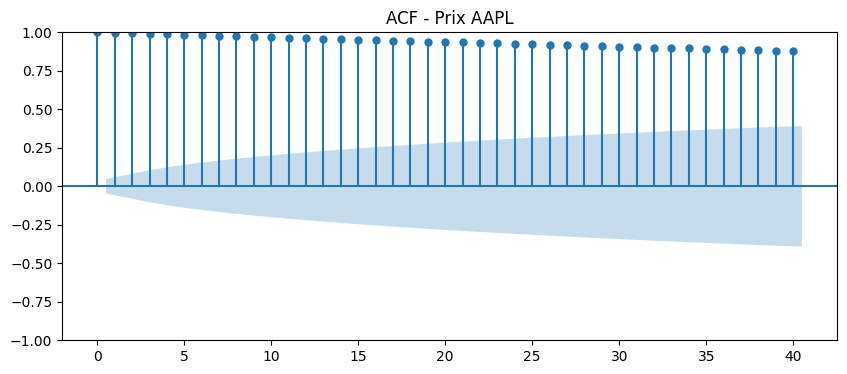

In [3]:
fig, ax = plt.subplots(figsize=(10, 4))
plot_acf(train["AAPL"].dropna(), ax=ax, lags=40)
plt.title("ACF - Prix AAPL")
plt.show()

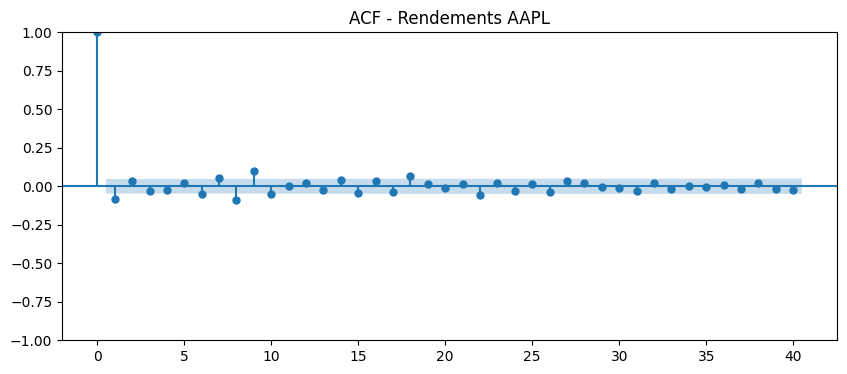

In [4]:
fig, ax = plt.subplots(figsize=(10, 4))
plot_acf(train["AAPL_Return"].dropna(), ax=ax, lags=40)
plt.title("ACF - Rendements AAPL")
plt.show()

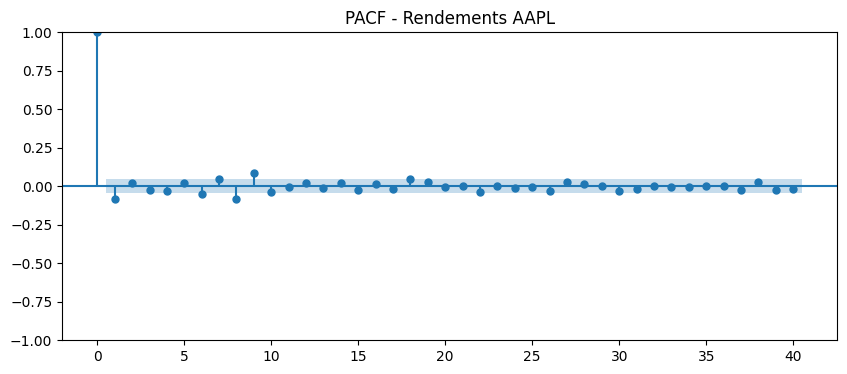

In [5]:
fig, ax = plt.subplots(figsize=(10, 4))
plot_pacf(train["AAPL_Return"].dropna(), ax=ax, lags=40)
plt.title("PACF - Rendements AAPL")
plt.show()

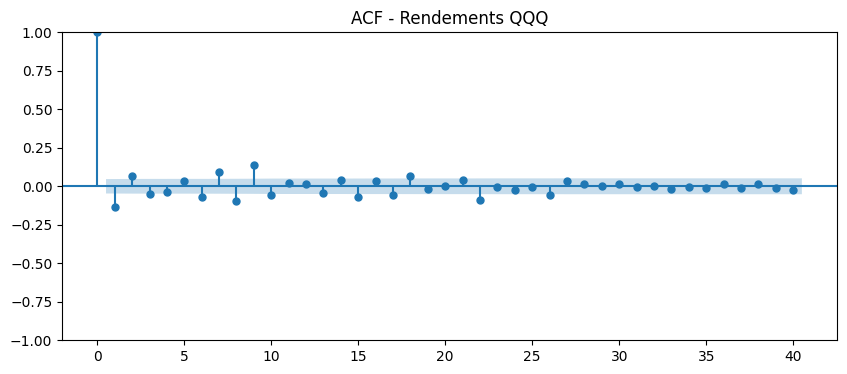

In [6]:
fig, ax = plt.subplots(figsize=(10, 4))
plot_acf(train["QQQ_Return"].dropna(), ax=ax, lags=40)
plt.title("ACF - Rendements QQQ")
plt.show()

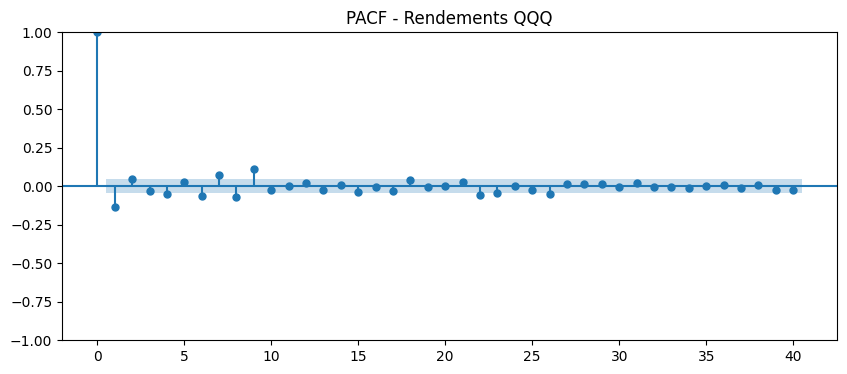

In [7]:
fig, ax = plt.subplots(figsize=(10, 4))
plot_pacf(train["QQQ_Return"].dropna(), ax=ax, lags=40)
plt.title("PACF - Rendements QQQ")
plt.show()

## Test ADF

In [8]:
def adf_test(series, name):
    result = adfuller(series.dropna())

    print("Série :", name)
    print("ADF Statistic :", result[0])
    print("p-value :", result[1])

    if result[1] < 0.05:
        print("Conclusion : série stationnaire")
    else:
        print("Conclusion : série non stationnaire")

In [9]:
adf_test(train["AAPL"], "AAPL Prix")
adf_test(train["AAPL_Return"], "AAPL Rendement")

Série : AAPL Prix
ADF Statistic : -0.7299185177574551
p-value : 0.8388470384394522
Conclusion : série non stationnaire
Série : AAPL Rendement
ADF Statistic : -13.575308834847197
p-value : 2.175338976787247e-25
Conclusion : série stationnaire


In [10]:
adf_test(train["QQQ"], "QQQ Prix")
adf_test(train["QQQ_Return"], "QQQ Rendement")

Série : QQQ Prix
ADF Statistic : 0.006535918774835945
p-value : 0.9590692758810945
Conclusion : série non stationnaire
Série : QQQ Rendement
ADF Statistic : -13.206366255657416
p-value : 1.0688173168667487e-24
Conclusion : série stationnaire


## Test KPSS

In [11]:
from statsmodels.tsa.stattools import kpss

In [12]:
def kpss_test(series, name):
    result = kpss(series.dropna(), regression="c", nlags="auto")

    print("Série :", name)
    print("KPSS Statistic :", result[0])
    print("p-value :", result[1])

    if result[1] < 0.05:
        print("Conclusion : série non stationnaire")
    else:
        print("Conclusion : série stationnaire")

In [13]:
kpss_test(train["AAPL"], "AAPL Prix")
kpss_test(train["AAPL_Return"], "AAPL Rendement")

Série : AAPL Prix
KPSS Statistic : 5.997606463156161
p-value : 0.01
Conclusion : série non stationnaire
Série : AAPL Rendement
KPSS Statistic : 0.21350718126351326
p-value : 0.1
Conclusion : série stationnaire


C:\Users\mariem\AppData\Local\Temp\ipykernel_31020\2836244782.py:2: InterpolationWarning: The test statistic is outside of the range of p-values available in the look-up table. The actual p-value is smaller than the p-value returned.
  result = kpss(series.dropna(), regression="c", nlags="auto")
C:\Users\mariem\AppData\Local\Temp\ipykernel_31020\2836244782.py:2: InterpolationWarning: The test statistic is outside of the range of p-values available in the look-up table. The actual p-value is greater than the p-value returned.
  result = kpss(series.dropna(), regression="c", nlags="auto")


In [14]:
kpss_test(train["QQQ"], "QQQ Prix")
kpss_test(train["QQQ_Return"], "QQQ Rendement")

Série : QQQ Prix
KPSS Statistic : 5.491236968120071
p-value : 0.01
Conclusion : série non stationnaire
Série : QQQ Rendement
KPSS Statistic : 0.09026945774960127
p-value : 0.1
Conclusion : série stationnaire


C:\Users\mariem\AppData\Local\Temp\ipykernel_31020\2836244782.py:2: InterpolationWarning: The test statistic is outside of the range of p-values available in the look-up table. The actual p-value is smaller than the p-value returned.
  result = kpss(series.dropna(), regression="c", nlags="auto")
C:\Users\mariem\AppData\Local\Temp\ipykernel_31020\2836244782.py:2: InterpolationWarning: The test statistic is outside of the range of p-values available in the look-up table. The actual p-value is greater than the p-value returned.
  result = kpss(series.dropna(), regression="c", nlags="auto")


## la décomposition
Pour les prix financiers, la saisonnalité classique est moins évidente, donc on peut faire une décomposition sur les rendements AAPL.

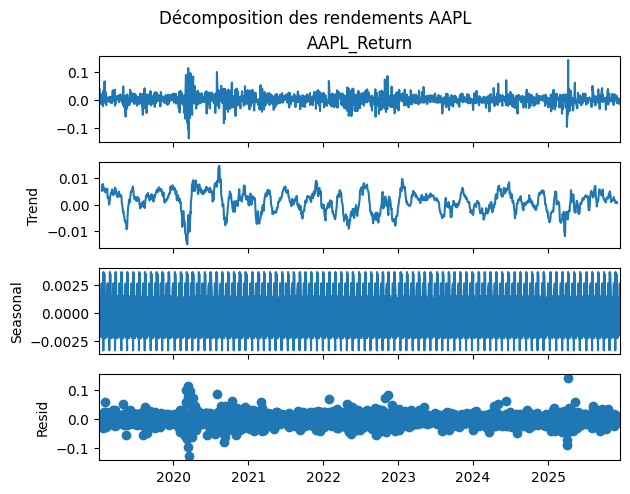

In [15]:
from statsmodels.tsa.seasonal import seasonal_decompose

decomposition = seasonal_decompose(
    train["AAPL_Return"].dropna(),
    model="additive",
    period=20
)

decomposition.plot()
plt.suptitle("Décomposition des rendements AAPL", y=1.02)
plt.show()

## analyser les ruptures / changements de régime

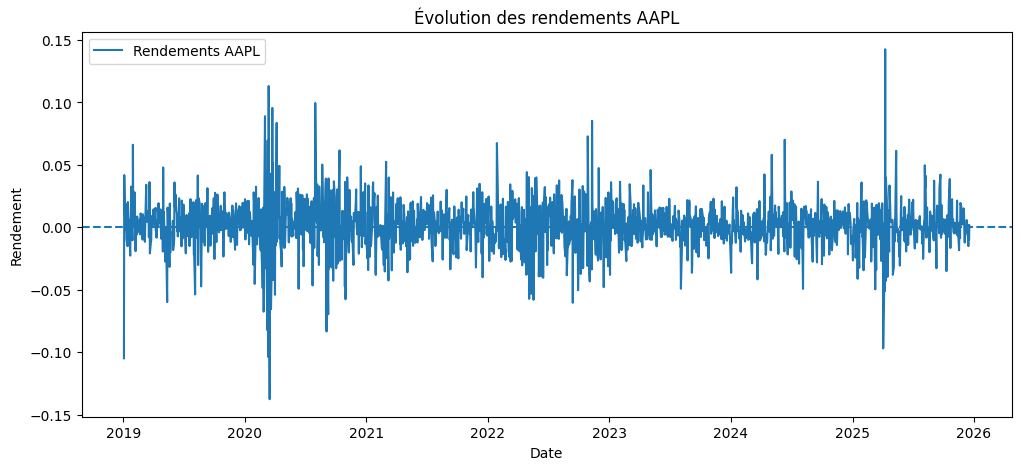

In [16]:
plt.figure(figsize=(12, 5))

plt.plot(train["AAPL_Return"], label="Rendements AAPL")
plt.axhline(0, linestyle="--")

plt.title("Évolution des rendements AAPL")
plt.xlabel("Date")
plt.ylabel("Rendement")
plt.legend()
plt.show()

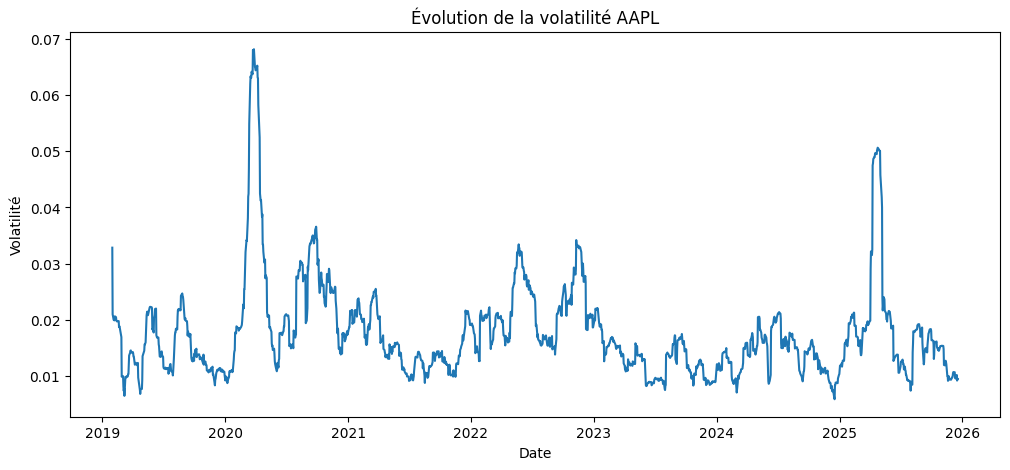

In [17]:
plt.figure(figsize=(12, 5))

plt.plot(train["AAPL_Volatility20"])

plt.title("Évolution de la volatilité AAPL")
plt.xlabel("Date")
plt.ylabel("Volatilité")

plt.show()